# Experiment Result Parser

This notebook evaluates an explicit list of experiment/model paths instead of auto-selecting the latest runs. Add run directories, `summary.json` files, or model weight files to `EXPERIMENT_PATHS`; nested lists are allowed when you want to keep related experiments grouped in the input. The notebook will flatten that list, load each run summary, and then:

- compares model parameter counts first,
- plots learning history for accuracy and F1,
- builds SI vs SD testing tables from the selected stored metrics.


In [ ]:
from __future__ import annotations

import json
from collections.abc import Iterable
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

PROJECT_ROOT = Path.cwd()
EXPERIMENT_ROOT = PROJECT_ROOT / "artifacts" / "experiments"

if not EXPERIMENT_ROOT.exists():
    raise FileNotFoundError(
        "Expected to run this notebook from the repository root so that 'artifacts/experiments' is available."
    )

# Put the exact experiments you want to evaluate here. Each entry may be:
# - a run directory: artifacts/experiments/sd/transformer/hand/20260505T190035Z
# - a summary file: artifacts/experiments/sd/transformer/hand/20260505T190035Z/summary.json
# - a model weights file: artifacts/experiments/sd/transformer/hand/20260505T190035Z/best.weights.h5
# Nested lists/tuples are flattened, so you can group related experiments while still evaluating them together.
EXPERIMENT_PATHS = [
    [
        # "artifacts/experiments/sd/gcn/hand/20260503T000033Z",
        # "artifacts/experiments/sd/lstm/hand/20260502T182524Z",
        # "artifacts/experiments/sd/transformer/hand/20260502T220632Z",
        # "artifacts/experiments/sd/cnn1d/hand/20260502T172408Z",
        # "artifacts/experiments/si/gcn/hand/20260503T074134Z",
        # "artifacts/experiments/si/lstm/hand/20260503T021824Z",
        # "artifacts/experiments/si/transformer/hand/20260503T055418Z",
        # "artifacts/experiments/si/cnn1d/hand/20260503T011439Z",

        "artifacts/experiments/sd/transformer/hand/20260503T153653Z",
        "artifacts/experiments/sd/transformer/hand/20260504T185457Z",
        "artifacts/experiments/sd/transformer/hand/20260505T190035Z",
        "artifacts/experiments/sd/transformer/hand/20260505T190431Z",
        
    ],
    # "artifacts/experiments/si/transformer/hand/20260504T163204Z/best.weights.h5",
]


def load_json(path: Path) -> dict:
    return json.loads(path.read_text())


def flatten_experiment_paths(paths: Iterable) -> list[str | Path]:
    flattened = []
    for item in paths:
        if isinstance(item, (str, Path)):
            flattened.append(item)
        elif isinstance(item, Iterable):
            flattened.extend(flatten_experiment_paths(item))
        else:
            raise TypeError(f"Unsupported experiment path entry: {item!r}")
    return flattened


def resolve_project_path(path_like: str | Path) -> Path:
    path = Path(path_like).expanduser()
    if not path.is_absolute():
        path = PROJECT_ROOT / path
    return path.resolve()


def resolve_run_dir(path_like: str | Path) -> Path:
    path = resolve_project_path(path_like)
    if path.is_dir():
        run_dir = path
    elif path.name == "summary.json":
        run_dir = path.parent
    elif path.suffix in {".h5", ".keras"} or path.name.endswith(".weights.h5"):
        run_dir = path.parent
    else:
        raise ValueError(
            f"Expected a run directory, summary.json, or model weights file; got: {path_like}"
        )

    summary_path = run_dir / "summary.json"
    if not summary_path.exists():
        raise FileNotFoundError(f"Could not find summary.json for selected experiment: {run_dir}")
    return run_dir


def infer_run_parts(run_dir: Path) -> tuple[str, str, str, str]:
    try:
        relative = run_dir.relative_to(EXPERIMENT_ROOT)
        scenario, model, modality, run_id = relative.parts[:4]
    except ValueError:
        scenario, model, modality, run_id = run_dir.parts[-4:]
    return scenario, model, modality, run_id


def display_path(path: Path) -> str:
    if path.is_relative_to(PROJECT_ROOT):
        return str(path.relative_to(PROJECT_ROOT))
    return str(path)


def run_to_row(run_dir: Path) -> dict:
    scenario, model, modality, run_id = infer_run_parts(run_dir)
    summary_path = run_dir / "summary.json"
    history_path = run_dir / "history.json"
    metrics_path = run_dir / "metrics.json"
    summary = load_json(summary_path)
    config = load_json(run_dir / "config.json")
    metrics = summary.get("metrics", {})
    return {
        "scenario": scenario,
        "model": model,
        "modality": modality,
        "combination": f"{model} | {modality}",
        "run_id": run_id,
        "run_dir": display_path(run_dir),
        "summary_path": display_path(summary_path),
        "history_path": display_path(history_path),
        "metrics_path": display_path(metrics_path),
        "config_path": display_path(run_dir / "config.json"),
        "parameter_count": summary.get("parameter_count"),
        "input_shape": tuple(summary.get("input_shape", [])),
        "frame_sample_count": config.get("frame_sample_count"),
        "seed": config.get("seed"),
        "train_size": summary.get("train_size"),
        "test_size": summary.get("test_size"),
        "num_classes": summary.get("num_classes"),
        "test_accuracy": metrics.get("accuracy"),
        "test_f1_score": metrics.get("f1_score"),
        "test_loss": metrics.get("loss"),
    }


def format_shape(shape) -> str:
    if not shape:
        return "?"
    return "x".join(str(part) for part in shape)


def add_display_labels(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy()
    duplicate_model = frame.duplicated("model", keep=False)
    labels = []
    for row_index, row in frame.iterrows():
        if duplicate_model.loc[row_index]:
            labels.append(
                f"{row['model']} | {row['modality']}\n"
                f"{row['scenario'].upper()} {format_shape(row['input_shape'])} seed={row['seed']}"
            )
        else:
            labels.append(f"{row['model']} | {row['modality']}")

    frame["display_label"] = labels
    duplicate_label = frame.duplicated("display_label", keep=False)
    frame.loc[duplicate_label, "display_label"] = (
        frame.loc[duplicate_label, "display_label"] + "\n" + frame.loc[duplicate_label, "run_id"]
    )

    palette = [
        f"#{int(r * 255):02x}{int(g * 255):02x}{int(b * 255):02x}"
        for r, g, b, _ in (plt.cm.tab20(index % 20) for index in range(len(frame)))
    ]
    frame["display_color"] = palette
    return frame


def collect_selected_runs(paths: Iterable) -> pd.DataFrame:
    run_dirs = []
    seen = set()
    for selected_path in flatten_experiment_paths(paths):
        run_dir = resolve_run_dir(selected_path)
        if run_dir not in seen:
            run_dirs.append(run_dir)
            seen.add(run_dir)

    if not run_dirs:
        raise ValueError("Add at least one experiment path to EXPERIMENT_PATHS.")

    frame = pd.DataFrame(run_to_row(run_dir) for run_dir in run_dirs)
    frame = frame.sort_values(["scenario", "model", "modality", "run_id"]).reset_index(drop=True)
    return add_display_labels(frame)


selected_runs = collect_selected_runs(EXPERIMENT_PATHS)
display(selected_runs)


,scenario,model,modality,combination,run_id,run_dir,summary_path,history_path,metrics_path,config_path,parameter_count,input_shape,frame_sample_count,seed,train_size,test_size,num_classes,test_accuracy,test_f1_score,test_loss,display_label,display_color
0,sd,transformer,hand,transformer | hand,20260503T153653Z,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,1039787,"(20, 210)",20,42,50456,32943,2731,0.000486,0.000000,7.948769,transformer | hand\nSD 20x210 seed=42,#1f77b4
1,sd,transformer,hand,transformer | hand,20260504T185457Z,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,1039787,"(30, 210)",30,42,50456,32943,2731,0.000486,0.000000,7.948839,transformer | hand\nSD 30x210 seed=42,#aec7e8
2,sd,transformer,hand,transformer | hand,20260505T190035Z,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,1039787,"(30, 210)",30,128,50456,32943,2731,0.551528,0.545560,2.085763,transformer | hand\nSD 30x210 seed=128,#ff7f0e
3,sd,transformer,hand,transformer | hand,20260505T190431Z,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,artifacts/experiments/sd/transformer/hand/2026...,1039787,"(20, 210)",20,128,50456,32943,2731,0.515527,0.509313,2.330356,transformer | hand\nSD 20x210 seed=128,#ffbb78


,display_label,scenario,model,modality,run_id,frame_sample_count,input_shape,seed
0,transformer | hand\nSD 20x210 seed=42,sd,transformer,hand,20260503T153653Z,20,"(20, 210)",42
1,transformer | hand\nSD 30x210 seed=42,sd,transformer,hand,20260504T185457Z,30,"(30, 210)",42
2,transformer | hand\nSD 30x210 seed=128,sd,transformer,hand,20260505T190035Z,30,"(30, 210)",128
3,transformer | hand\nSD 20x210 seed=128,sd,transformer,hand,20260505T190431Z,20,"(20, 210)",128


display_label,transformer | hand\nSD 20x210 seed=42,transformer | hand\nSD 30x210 seed=42,transformer | hand\nSD 30x210 seed=128,transformer | hand\nSD 20x210 seed=128
scenario,sd,sd,sd,sd
model,transformer,transformer,transformer,transformer
modality,hand,hand,hand,hand
run_id,20260503T153653Z,20260504T185457Z,20260505T190035Z,20260505T190431Z
frame_sample_count,20,30,30,20
input_shape,"(20, 210)","(30, 210)","(30, 210)","(20, 210)"
seed,42,42,128,128


,display_label,model,modality,scenario,run_id,frame_sample_count,seed,parameter_count,input_shape,num_classes
0,transformer | hand\nSD 20x210 seed=42,transformer,hand,sd,20260503T153653Z,20,42,1039787,"(20, 210)",2731
1,transformer | hand\nSD 30x210 seed=42,transformer,hand,sd,20260504T185457Z,30,42,1039787,"(30, 210)",2731
2,transformer | hand\nSD 30x210 seed=128,transformer,hand,sd,20260505T190035Z,30,128,1039787,"(30, 210)",2731
3,transformer | hand\nSD 20x210 seed=128,transformer,hand,sd,20260505T190431Z,20,128,1039787,"(20, 210)",2731


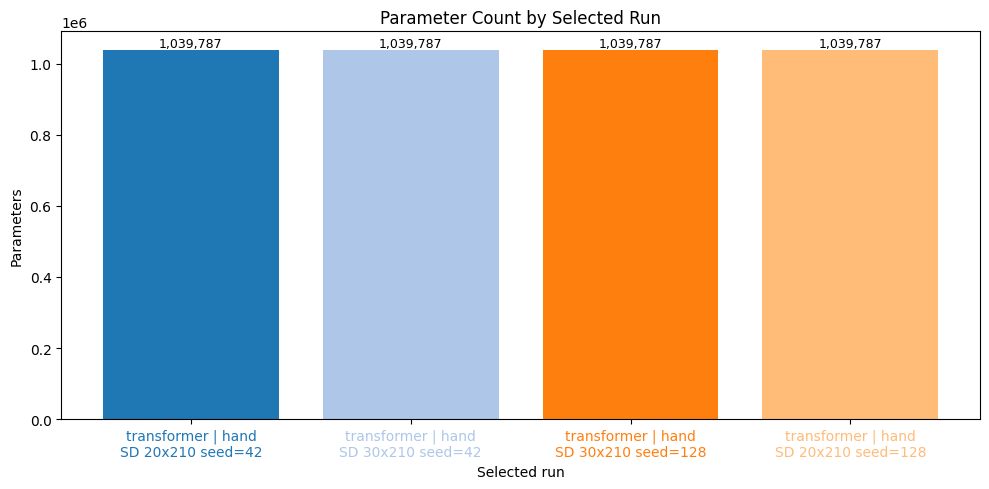

In [93]:
# Config and parameter comparison
def flatten_config(config: dict, prefix: str = "") -> dict:
    flattened = {}
    for key, value in config.items():
        full_key = f"{prefix}.{key}" if prefix else key
        if isinstance(value, dict):
            flattened.update(flatten_config(value, full_key))
        elif isinstance(value, list):
            flattened[full_key] = tuple(value)
        else:
            flattened[full_key] = value
    return flattened


config_rows = []
for run in selected_runs.itertuples(index=False):
    config_path = PROJECT_ROOT / run.config_path
    config = flatten_config(load_json(config_path))
    config_rows.append(
        {
            "display_label": run.display_label,
            "scenario": run.scenario,
            "model": run.model,
            "modality": run.modality,
            "run_id": run.run_id,
            **config,
        }
    )

config_table = pd.DataFrame(config_rows)
identity_columns = ["display_label", "scenario", "model", "modality", "run_id"]
config_columns = [column for column in config_table.columns if column not in identity_columns]
varying_config_columns = [
    column
    for column in config_columns
    if config_table[column].nunique(dropna=False) > 1
]

display(config_table[identity_columns + varying_config_columns])

config_compare = config_table.set_index(identity_columns).T
config_compare = config_compare.loc[varying_config_columns]
display(config_compare)

parameter_table = (
    selected_runs[[
        "display_label",
        "model",
        "modality",
        "scenario",
        "run_id",
        "frame_sample_count",
        "seed",
        "parameter_count",
        "input_shape",
        "num_classes",
    ]]
    .sort_values(["parameter_count", "model", "modality", "scenario", "run_id"], ascending=[False, True, True, True, True])
    .reset_index(drop=True)
)
display(parameter_table)

parameter_plot = selected_runs.sort_values(
    ["parameter_count", "model", "modality", "scenario", "run_id"],
    ascending=[False, True, True, True, True],
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(max(10, 1.9 * len(parameter_plot)), 5))
ax.bar(parameter_plot["display_label"], parameter_plot["parameter_count"], color=parameter_plot["display_color"])
ax.set_title("Parameter Count by Selected Run")
ax.set_ylabel("Parameters")
ax.set_xlabel("Selected run")
ax.tick_params(axis="x", rotation=0)
for tick, color in zip(ax.get_xticklabels(), parameter_plot["display_color"]):
    tick.set_color(color)
for index, value in enumerate(parameter_plot["parameter_count"]):
    ax.text(index, value, f"{value:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()


,scenario,model,modality,series,run_id,epoch,split,metric,value
0,sd,transformer,hand,transformer | hand\nSD 20x210 seed=42,20260503T153653Z,1,train,accuracy,0.000277
1,sd,transformer,hand,transformer | hand\nSD 20x210 seed=42,20260503T153653Z,2,train,accuracy,0.000337
2,sd,transformer,hand,transformer | hand\nSD 20x210 seed=42,20260503T153653Z,3,train,accuracy,0.000297
3,sd,transformer,hand,transformer | hand\nSD 20x210 seed=42,20260503T153653Z,4,train,accuracy,0.000396
4,sd,transformer,hand,transformer | hand\nSD 20x210 seed=42,20260503T153653Z,5,train,accuracy,0.000515


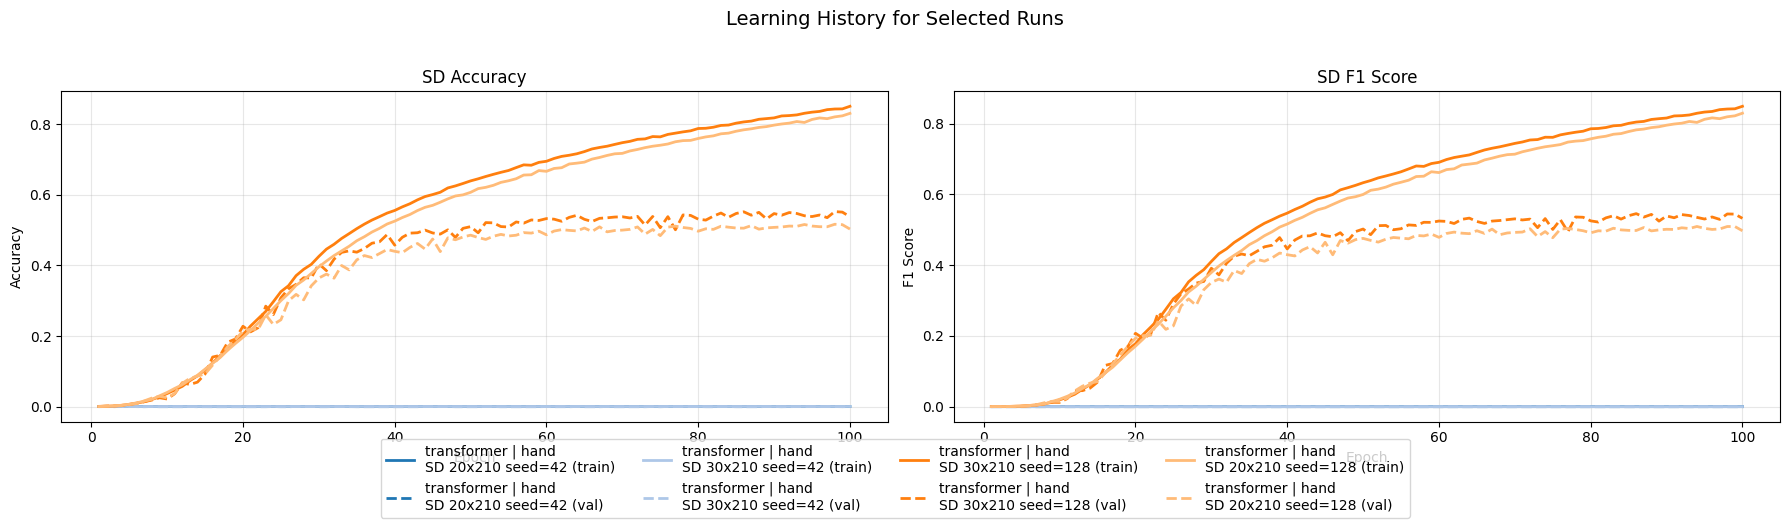

In [ ]:
def build_history_frame(selected_frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for run in selected_frame.itertuples(index=False):
        history = load_json(PROJECT_ROOT / run.history_path)
        keys = {
            ("train", "accuracy"): "accuracy",
            ("val", "accuracy"): "val_accuracy",
            ("train", "f1_score"): "f1_score",
            ("val", "f1_score"): "val_f1_score",
        }
        for (split, metric), history_key in keys.items():
            values = history.get(history_key, [])
            for epoch, value in enumerate(values, start=1):
                rows.append(
                    {
                        "scenario": run.scenario,
                        "model": run.model,
                        "modality": run.modality,
                        "series": run.display_label,
                        "run_id": run.run_id,
                        "epoch": epoch,
                        "split": split,
                        "metric": metric,
                        "value": value,
                    }
                )
    return pd.DataFrame(rows)


history_df = build_history_frame(selected_runs)
display(history_df.head())

preferred_scenarios = ["sd", "si"]
present_scenarios = set(history_df["scenario"])
scenario_order = [scenario for scenario in preferred_scenarios if scenario in present_scenarios]
scenario_order.extend(sorted(present_scenarios - set(scenario_order)))
if not scenario_order:
    raise ValueError("No history rows were built from the selected experiments.")

metric_specs = [("accuracy", "Accuracy"), ("f1_score", "F1 Score")]
all_series = selected_runs["display_label"].tolist()
color_map = dict(zip(selected_runs["display_label"], selected_runs["display_color"]))

fig, axes = plt.subplots(len(scenario_order), 2, figsize=(18, 5 * len(scenario_order)), sharex=True, squeeze=False)
legend_handles = {}

for row_index, scenario in enumerate(scenario_order):
    scenario_history = history_df[history_df["scenario"] == scenario].copy()
    series_names = [series for series in all_series if series in set(scenario_history["series"])]

    for col_index, (metric_name, title) in enumerate(metric_specs):
        ax = axes[row_index, col_index]
        metric_history = scenario_history[scenario_history["metric"] == metric_name]

        for series_name in series_names:
            series_history = metric_history[metric_history["series"] == series_name]
            for split, linestyle in [("train", "-"), ("val", "--")]:
                line_history = series_history[series_history["split"] == split]
                if line_history.empty:
                    continue
                label = f"{series_name} ({split})"
                line, = ax.plot(
                    line_history["epoch"],
                    line_history["value"],
                    color=color_map[series_name],
                    linestyle=linestyle,
                    linewidth=2,
                    label=label,
                )
                legend_handles.setdefault(label, line)

        ax.set_title(f"{scenario.upper()} {title}")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(title)
        ax.grid(alpha=0.3)

fig.legend(
    legend_handles.values(),
    legend_handles.keys(),
    loc="lower center",
    ncol=4,
    bbox_to_anchor=(0.5, -0.01),
)
fig.suptitle("Learning History for Selected Runs", y=1.02, fontsize=14)
fig.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()


In [ ]:
# Testing comparison tables for the selected SI and SD runs
test_results_long = (
    selected_runs[[
        "display_label",
        "scenario",
        "model",
        "modality",
        "run_id",
        "frame_sample_count",
        "seed",
        "test_accuracy",
        "test_f1_score",
        "test_loss",
        "test_size",
    ]]
    .sort_values(["scenario", "model", "modality"])
    .reset_index(drop=True)
)
display(test_results_long)

test_results_compare = (
    selected_runs.pivot_table(
        index=["display_label", "model", "modality", "run_id"],
        columns="scenario",
        values=["test_accuracy", "test_f1_score", "test_loss", "run_id"],
        aggfunc="first",
    )
    .swaplevel(0, 1, axis=1)
    .sort_index(axis=1, level=[0, 1])
)
display(test_results_compare)

best_by_scenario = (
    selected_runs.sort_values(["scenario", "test_accuracy", "test_f1_score"], ascending=[True, False, False])
    .groupby("scenario", as_index=False)
    .head(1)
    [["display_label", "scenario", "model", "modality", "run_id", "frame_sample_count", "seed", "test_accuracy", "test_f1_score", "test_loss"]]
    .reset_index(drop=True)
)
display(best_by_scenario)

selected_run_paths = selected_runs[["display_label", "scenario", "model", "modality", "run_id", "frame_sample_count", "seed", "input_shape", "run_dir"]].copy()
display(selected_run_paths)


,display_label,scenario,model,modality,run_id,frame_sample_count,seed,test_accuracy,test_f1_score,test_loss,test_size
0,transformer | hand\nSD 20x210 seed=42,sd,transformer,hand,20260503T153653Z,20,42,0.000486,0.000000,7.948769,32943
1,transformer | hand\nSD 30x210 seed=42,sd,transformer,hand,20260504T185457Z,30,42,0.000486,0.000000,7.948839,32943
2,transformer | hand\nSD 30x210 seed=128,sd,transformer,hand,20260505T190035Z,30,128,0.551528,0.545560,2.085763,32943
3,transformer | hand\nSD 20x210 seed=128,sd,transformer,hand,20260505T190431Z,20,128,0.515527,0.509313,2.330356,32943


## Sample Count Effect

Use `EXPERIMENT` to choose which run should represent each scenario, model, and frame sample count. The charts below compare test accuracy and F1 score as the sample count increases, with SD and SI shown as separate figures.


,scenario,model,sample_count,configured_sample_count,run_id,run_dir,train_accuracy,test_accuracy,train_f1_score,test_f1_score
0,sd,cnn1d,10,10,20260502T172408Z,artifacts/experiments/sd/cnn1d/hand/20260502T1...,0.264666,0.156634,0.249724,0.138659
1,sd,cnn1d,20,20,20260503T085939Z,artifacts/experiments/sd/cnn1d/hand/20260503T0...,0.337799,0.184288,0.327213,0.168941
2,sd,cnn1d,30,30,20260504T175400Z,artifacts/experiments/sd/cnn1d/hand/20260504T1...,0.354527,0.185927,0.345202,0.171379
3,sd,gcn,10,10,20260503T000033Z,artifacts/experiments/sd/gcn/hand/20260503T000...,0.216030,0.147983,0.202770,0.134865
4,sd,gcn,20,20,20260503T180131Z,artifacts/experiments/sd/gcn/hand/20260503T180...,0.260722,0.172480,0.249391,0.160473
5,sd,gcn,30,30,20260504T191712Z,artifacts/experiments/sd/gcn/hand/20260504T191...,0.253805,0.166196,0.242533,0.154500
6,sd,lstm,10,10,20260502T182524Z,artifacts/experiments/sd/lstm/hand/20260502T18...,0.382630,0.248581,0.366453,0.231201
7,sd,lstm,20,20,20260503T100158Z,artifacts/experiments/sd/lstm/hand/20260503T10...,0.570557,0.364144,0.560763,0.349979
8,sd,lstm,30,30,20260504T180433Z,artifacts/experiments/sd/lstm/hand/20260504T18...,0.629400,0.408068,0.621504,0.394907
9,sd,transformer,10,10,20260502T220632Z,artifacts/experiments/sd/transformer/hand/2026...,0.752656,0.411377,0.751647,0.405521


test_accuracy                   test_f1_score           \
sample_count                    10       20       30            10       20   
scenario model                                                                
sd       cnn1d            0.156634 0.184288 0.185927      0.138659 0.168941   
         gcn              0.147983 0.172480 0.166196      0.134865 0.160473   
         lstm             0.248581 0.364144 0.408068      0.231201 0.349979   
         transformer      0.411377 0.515527 0.551528      0.405521 0.509313   
si       cnn1d            0.158708 0.182903 0.181567      0.141911 0.170343   
         gcn              0.139704 0.176831 0.162412      0.125559 0.166230   
         lstm             0.238639 0.338666 0.363923      0.224887 0.327167   
         transformer      0.386965 0.485747 0.515255      0.382210 0.481311   

                              train_accuracy                   train_f1_score  \
sample_count               30             10       20       30             10   
scenario model                                                                  
sd       cnn1d       0.171379       0.264666 0.337799 0.354527       0.249724   
         gcn         0.154500       0.216030 0.260722 0.253805       0.202770   
         lstm        0.394907       0.382630 0.570557 0.629400       0.366453   
         transformer 0.545560       0.752656 0.830050 0.850067       0.751647   
si       cnn1d       0.167998       0.284692 0.350371 0.370189       0.273997   
         gcn         0.152089       0.221630 0.274188 0.265964       0.209978   
         lstm        0.355053       0.399283 0.592929 0.647509       0.387456   
         transformer 0.511443       0.761207 0.841809 0.862480       0.760538   

                                        
sample_count               20       30  
scenario model                          
sd       cnn1d       0.327213 0.345202  
         gcn         0.249391 0.242533  
         lstm        0.560763 0.621504  
         transformer 0.829443 0.848952  
si       cnn1d       0.343056 0.363462  
         gcn         0.265028 0.256239  
         lstm        0.587514 0.643742  
         transformer 0.841216 0.861963

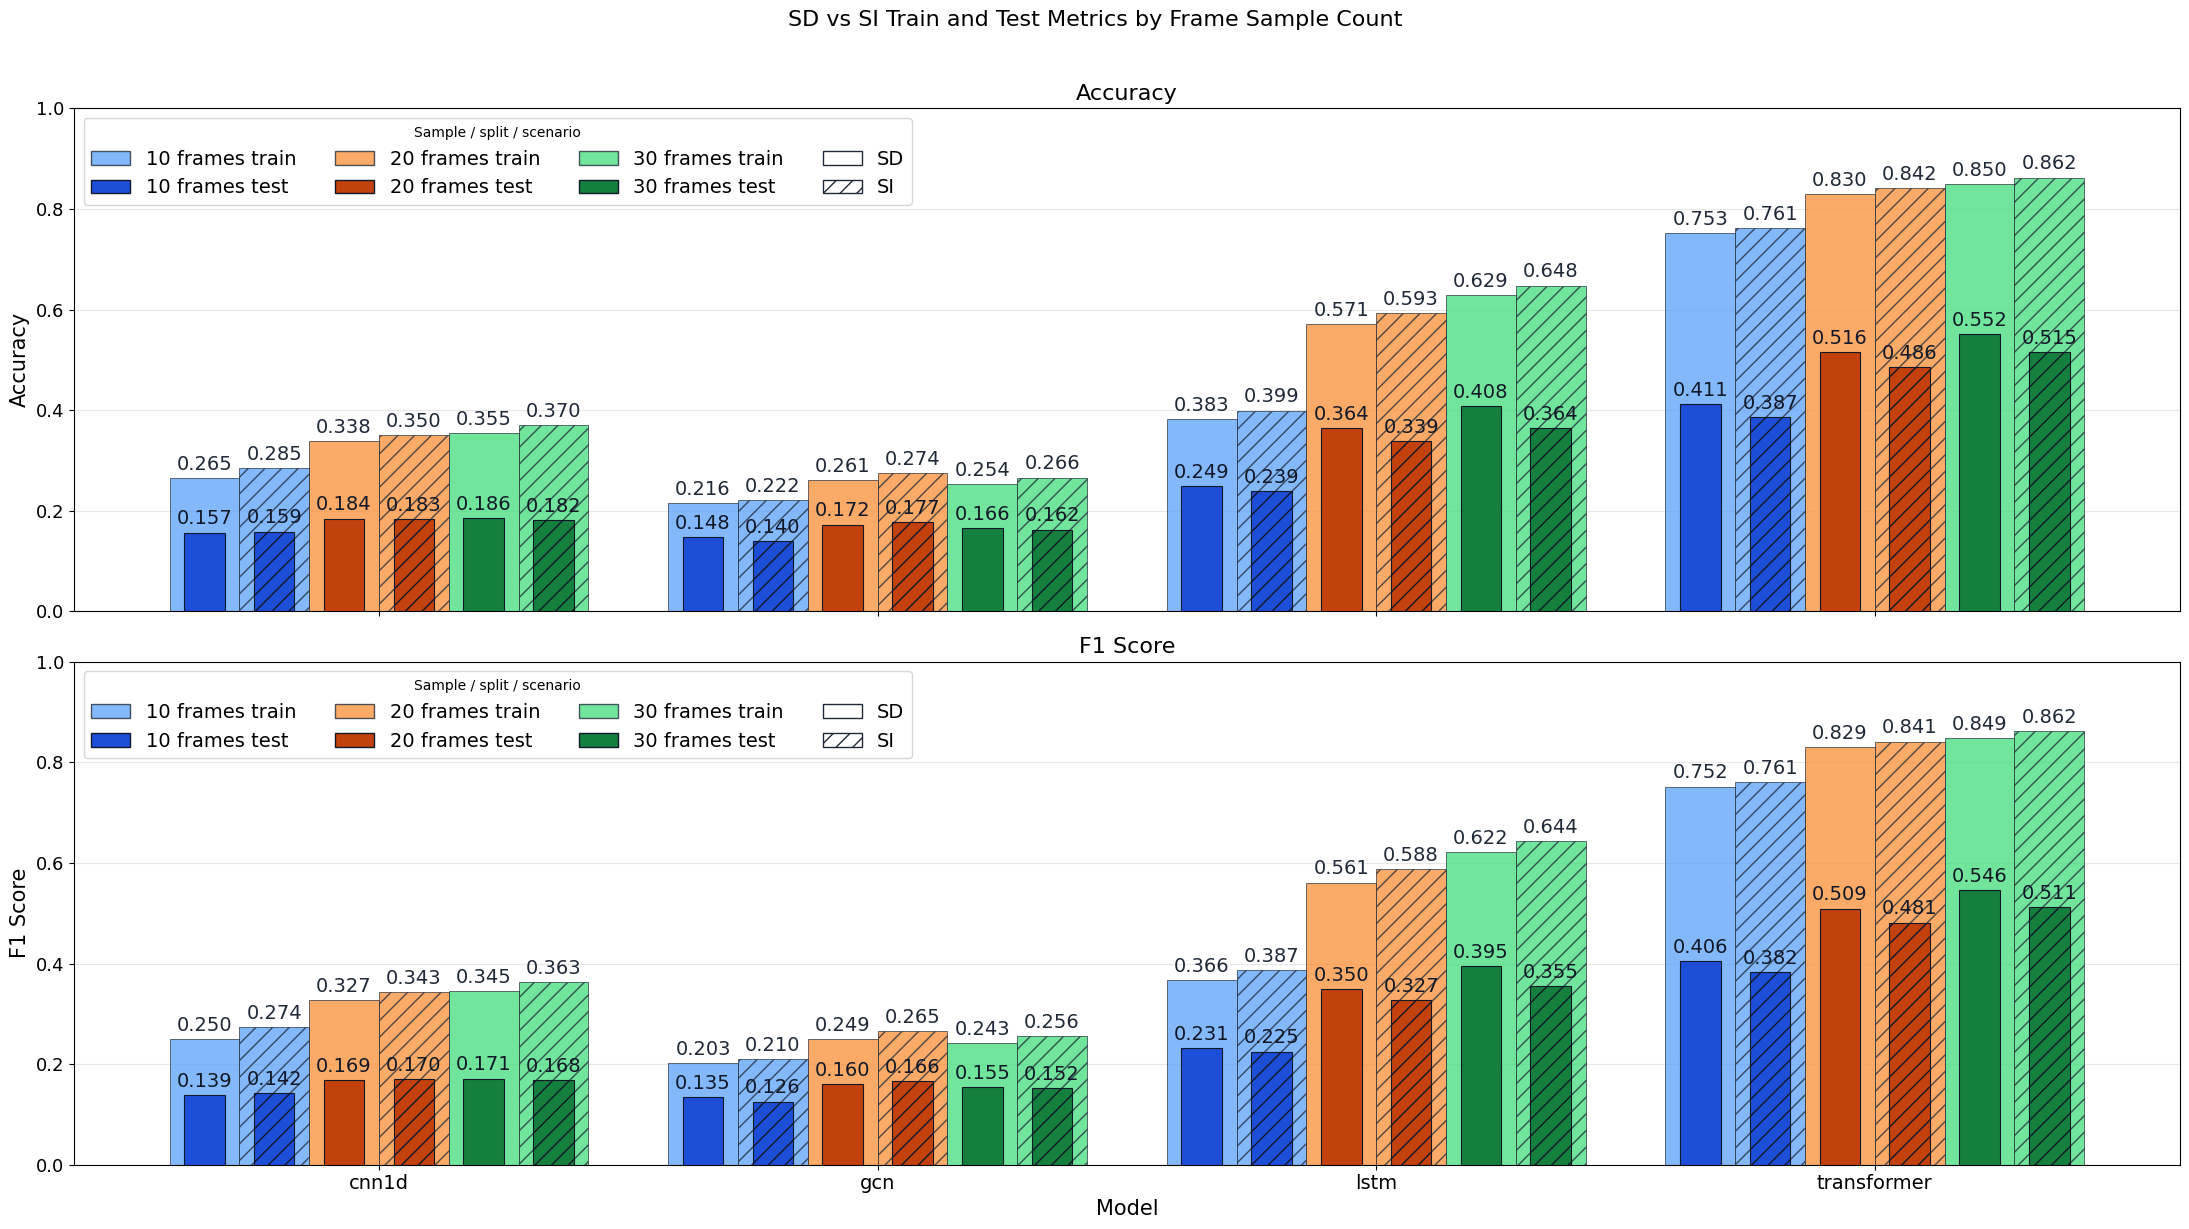

In [ ]:
EXPERIMENT = {
    "sd": {
        "cnn1d": {
            10: "artifacts/experiments/sd/cnn1d/hand/20260502T172408Z",
            20: "artifacts/experiments/sd/cnn1d/hand/20260503T085939Z",
            30: "artifacts/experiments/sd/cnn1d/hand/20260504T175400Z",
        },
        "gcn": {
            10: "artifacts/experiments/sd/gcn/hand/20260503T000033Z",
            20: "artifacts/experiments/sd/gcn/hand/20260503T180131Z",
            30: "artifacts/experiments/sd/gcn/hand/20260504T191712Z",
        },
        "lstm": {
            10: "artifacts/experiments/sd/lstm/hand/20260502T182524Z",
            20: "artifacts/experiments/sd/lstm/hand/20260503T100158Z",
            30: "artifacts/experiments/sd/lstm/hand/20260504T180433Z",
        },
        "transformer": {
            10: "artifacts/experiments/sd/transformer/hand/20260502T220632Z",
            20: "artifacts/experiments/sd/transformer/hand/20260505T190431Z",
            30: "artifacts/experiments/sd/transformer/hand/20260505T190035Z",
        },
    },
    "si": {
        "cnn1d": {
            10: "artifacts/experiments/si/cnn1d/hand/20260503T011439Z",
            20: "artifacts/experiments/si/cnn1d/hand/20260503T175651Z",
            30: "artifacts/experiments/si/cnn1d/hand/20260504T163204Z",
        },
        "gcn": {
            10: "artifacts/experiments/si/gcn/hand/20260503T074134Z",
            20: "artifacts/experiments/si/gcn/hand/20260504T023331Z",
            30: "artifacts/experiments/si/gcn/hand/20260504T163204Z",
        },
        "lstm": {
            10: "artifacts/experiments/si/lstm/hand/20260503T021824Z",
            20: "artifacts/experiments/si/lstm/hand/20260503T191204Z",
            30: "artifacts/experiments/si/lstm/hand/20260504T163205Z",
        },
        "transformer": {
            10: "artifacts/experiments/si/transformer/hand/20260503T055418Z",
            20: "artifacts/experiments/si/transformer/hand/20260504T004621Z",
            30: "artifacts/experiments/si/transformer/hand/20260504T163204Z",
        },
    },
}



def last_history_value(history: dict, key: str):
    values = history.get(key, [])
    if not values:
        return None
    return values[-1]


def collect_sample_effect_frame(experiment: dict) -> pd.DataFrame:
    rows = []
    for scenario, model_runs in experiment.items():
        for model, sample_runs in model_runs.items():
            for sample_count, selected_path in sample_runs.items():
                run_dir = resolve_run_dir(selected_path)
                summary = load_json(run_dir / "summary.json")
                config = load_json(run_dir / "config.json")
                history = load_json(run_dir / "history.json")
                metrics = summary.get("metrics", {})
                rows.append(
                    {
                        "scenario": scenario,
                        "model": model,
                        "sample_count": sample_count,
                        "configured_sample_count": config.get("frame_sample_count"),
                        "run_id": run_dir.name,
                        "run_dir": display_path(run_dir),
                        "train_accuracy": last_history_value(history, "accuracy"),
                        "test_accuracy": metrics.get("accuracy"),
                        "train_f1_score": last_history_value(history, "f1_score"),
                        "test_f1_score": metrics.get("f1_score"),
                    }
                )
    return (
        pd.DataFrame(rows)
        .sort_values(["scenario", "model", "sample_count"])
        .reset_index(drop=True)
    )


sample_effect_df = collect_sample_effect_frame(EXPERIMENT)
display(sample_effect_df)

sample_effect_compare = sample_effect_df.pivot_table(
    index=["scenario", "model"],
    columns="sample_count",
    values=["train_accuracy", "test_accuracy", "train_f1_score", "test_f1_score"],
    aggfunc="first",
).sort_index(axis=1, level=[0, 1])
display(sample_effect_compare)

metric_specs = [
    ("accuracy", "Accuracy", "train_accuracy", "test_accuracy"),
    ("f1_score", "F1 Score", "train_f1_score", "test_f1_score"),
]
sample_colors = {
    10: {"train": "#60a5fa", "test": "#1d4ed8"},
    20: {"train": "#fb923c", "test": "#c2410c"},
    30: {"train": "#4ade80", "test": "#15803d"},
}
scenario_hatches = {
    "sd": "",
    "si": "//",
}
scenario_order = [scenario for scenario in ["sd", "si"] if scenario in set(sample_effect_df["scenario"])]
model_order = [model for model in ["cnn1d", "gcn", "lstm", "transformer"] if model in set(sample_effect_df["model"])]
sample_counts = sorted(sample_effect_df["sample_count"].unique())

fig, axes = plt.subplots(2, 1, figsize=(22, 12), sharex=True)
x_positions = list(range(len(model_order)))
bars_per_model = max(1, len(sample_counts) * len(scenario_order))
train_bar_width = min(0.14, 0.86 / bars_per_model)
test_bar_width = train_bar_width * 0.58

for ax, (_, metric_label, train_column, test_column) in zip(axes, metric_specs):
    metric_max = 0
    for sample_index, sample_count in enumerate(sample_counts):
        for scenario_index, scenario in enumerate(scenario_order):
            scenario_sample_df = (
                sample_effect_df[
                    (sample_effect_df["scenario"] == scenario)
                    & (sample_effect_df["sample_count"] == sample_count)
                ]
                .set_index("model")
            )
            slot_index = sample_index * len(scenario_order) + scenario_index
            offset = (slot_index - (bars_per_model - 1) / 2) * train_bar_width
            x_values = [x + offset for x in x_positions]
            train_values = scenario_sample_df.reindex(model_order)[train_column].tolist()
            test_values = scenario_sample_df.reindex(model_order)[test_column].tolist()
            metric_max = max(
                metric_max,
                max([value for value in train_values + test_values if pd.notna(value)], default=0),
            )
            colors = sample_colors.get(sample_count, {"train": "#94a3b8", "test": "#475569"})
            hatch = scenario_hatches.get(scenario, "")

            train_bars = ax.bar(
                x_values,
                train_values,
                width=train_bar_width,
                color=colors["train"],
                edgecolor="#1f2937",
                linewidth=0.6,
                alpha=0.78,
                hatch=hatch,
                zorder=2,
            )
            test_bars = ax.bar(
                x_values,
                test_values,
                width=test_bar_width,
                color=colors["test"],
                edgecolor="#111827",
                linewidth=0.8,
                hatch=hatch,
                zorder=3,
            )

            train_labels = [f"{value:.3f}" if pd.notna(value) else "" for value in train_values]
            test_labels = [f"{value:.3f}" if pd.notna(value) else "" for value in test_values]
            ax.bar_label(train_bars, labels=train_labels, padding=3, fontsize=14, color="#1f2937")
            ax.bar_label(test_bars, labels=test_labels, padding=3, fontsize=14, color="#111827")

    sample_handles = []
    for sample_count in sample_counts:
        colors = sample_colors.get(sample_count, {"train": "#94a3b8", "test": "#475569"})
        sample_handles.extend(
            [
                plt.Rectangle(
                    (0, 0),
                    1,
                    1,
                    facecolor=colors["train"],
                    edgecolor="#1f2937",
                    alpha=0.78,
                    label=f"{sample_count} frames train",
                ),
                plt.Rectangle(
                    (0, 0),
                    1,
                    1,
                    facecolor=colors["test"],
                    edgecolor="#111827",
                    label=f"{sample_count} frames test",
                ),
            ]
        )
    scenario_handles = [
        plt.Rectangle(
            (0, 0),
            1,
            1,
            facecolor="white",
            edgecolor="#1f2937",
            hatch=scenario_hatches.get(scenario, ""),
            label=scenario.upper(),
        )
        for scenario in scenario_order
    ]

    ax.set_title(metric_label, fontsize=16)
    ax.set_ylabel(metric_label, fontsize=15)
    ax.set_xticks(x_positions)
    ax.set_xticklabels(model_order, fontsize=14)
    ax.set_ylim(0, min(1.0, max(0.05, metric_max * 1.18)))
    ax.tick_params(axis="y", labelsize=13)
    ax.grid(axis="y", alpha=0.3, zorder=1)
    ax.legend(handles=sample_handles + scenario_handles, title="Sample / split / scenario", ncol=4, fontsize=14)

axes[-1].set_xlabel("Model", fontsize=15)
fig.suptitle("SD vs SI Train and Test Metrics by Frame Sample Count", y=1.02, fontsize=16)
fig.tight_layout()
plt.show()
